# Milestone 2, Part 2: Baseline Conditional Generation

This notebook covers the second Milestone 2 task: **run baseline conditional generation**. It uses the pipeline integrated in Part 1 (`t2i.py`) to generate all 20 Milestone 1 baseline prompts with 3 seeds each, at fixed settings. It then checks that the outputs match their prompts and not just that the model can produce *an* image.

- Every image is saved with a JSON file holding its prompt, seed, sampler, step count, guidance scale, timings, GPU memory and package versions. `manifest.jsonl` lists them all.
- Runs resume: an image whose JSON file exists is skipped, so a Colab disconnect loses nothing.
- Prompt alignment is measured with CLIP ViT-B/32, the Milestone 1 model, which is a different network from the CLIP ViT-L/14 encoder that conditions Stable Diffusion. FID and Inception Score belong to Milestone 3.

Sections 3 to 5 run the guidance-scale, sampler and noise-schedule experiments on six of the prompts, and Section 6 joins every figure into the samples gallery PDF.

## 1. Setup

In [1]:
# Find the repo, move into the notebook folder, and pick a device
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/rasmussenj03/IE7615-Group3-Project2.git"
WORK_DIR = "Milestone 2"  # folder holding the notebooks, relative to the repo root
COLAB_USE_DRIVE = True  # False -> clone into /content (outputs are lost when the runtime ends)
COLAB_REPO_DIR = ("/content/drive/MyDrive/IE7615-Group3-Project2" if COLAB_USE_DRIVE
                  else "/content/IE7615-Group3-Project2")

if "google.colab" in sys.modules:
    if COLAB_USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
    if not Path(COLAB_REPO_DIR, "requirements.txt").is_file():
        from google.colab import userdata
        token = userdata.get("GITHUB_TOKEN")  # Colab secret holding a GitHub access token
        clone = subprocess.run(["git", "clone", "-q", REPO_URL.replace("https://", f"https://{token}@"),
                                COLAB_REPO_DIR], capture_output=True)
        if clone.returncode != 0:
            raise RuntimeError("git clone failed - check the GITHUB_TOKEN secret and repo access")
        subprocess.run(["git", "-C", COLAB_REPO_DIR, "remote", "set-url", "origin", REPO_URL])
    root = Path(COLAB_REPO_DIR)
    # Install the pinned packages (local runs use the .venv instead)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(root / "requirements.txt")],
                   check=True)
else:
    root = Path.cwd()
    while not (root / "requirements.txt").exists() and root != root.parent:
        root = root.parent

PROJECT_ROOT = root
os.chdir(PROJECT_ROOT / WORK_DIR)
sys.path.insert(0, str(Path.cwd()))  # t2i.py and lora.py live next to the notebooks

import torch
if torch.cuda.is_available():
    device = "cuda"
    device_name = "cuda - " + torch.cuda.get_device_name(0)
elif torch.backends.mps.is_available():
    device = device_name = "mps"
else:
    device = device_name = "cpu"
print("Project root:", PROJECT_ROOT)
print("Working folder:", Path.cwd())
print("PyTorch", torch.__version__, "| device:", device_name)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root: /content/drive/MyDrive/IE7615-Group3-Project2
Working folder: /content/drive/MyDrive/IE7615-Group3-Project2/Milestone 2
PyTorch 2.8.0+cu128 | device: cuda - Tesla T4


In [2]:
# Imports
import json
import time
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

import t2i

assert device == "cuda" or os.environ.get("M2_ALLOW_CPU"), \
    "This notebook needs a CUDA GPU (set M2_ALLOW_CPU=1 to try anyway; it will be very slow)"

In [3]:
# Paths and experiment settings
M1_DIR = Path("..") / "Milestone 1"
BASELINE_DIR = M1_DIR / "Project2_Baseline"
with open(BASELINE_DIR / "data" / "baseline_prompts.json", encoding="utf-8") as f:
    baseline = json.load(f)
by_id = {b["prompt_id"]: b for b in baseline}

OUT_DIR = Path("outputs")
GEN_DIR = OUT_DIR / "generated"
FIG_DIR = OUT_DIR / "figures"
LOG_DIR = OUT_DIR / "logs"
for d in (GEN_DIR, FIG_DIR, LOG_DIR):
    d.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 4                   # images per UNet batch (x2 with guidance); lower it if CUDA runs out of memory

# Baseline settings (held fixed whenever a sweep varies something else)
BASE = dict(sampler="ddim", steps=50, guidance_scale=7.5)
SEED_OFFSETS = [0, 100, 200]     # seeds = Milestone 1 generation_seed + offset

In [4]:
# Load the integrated pipeline and the CLIP scorer
c = t2i.load_components(t2i.MODEL_ID, device)
TAG = "base"   # names the output folders; a later fine-tuned run can use "lora"
scorer = t2i.ClipScorer(device=device)
all_prompts = [b["prompt"] for b in baseline]
all_text = scorer.text_embeds(all_prompts)
pidx = {b["prompt_id"]: i for i, b in enumerate(baseline)}

def job(pid, seed_offset=0, **kw):
    b = by_id[pid]
    j = {"prompt_id": pid, "prompt": b["prompt"], "seed": b["generation_seed"] + seed_offset,
         "seed_offset": seed_offset, **BASE, "model_variant": TAG}
    j.update(kw)
    return j

def score(records, out_dir):
    """Attach CLIP score, top-1 retrieval among the 20 prompts, and saturation to each record."""
    imgs = [t2i.load_image(out_dir, r) for r in records]
    emb = scorer.image_embeds(imgs)
    tgt = [pidx[r["prompt_id"]] for r in records]
    sims = emb @ all_text.T
    for r, e, s, i, t in zip(records, emb, sims, imgs, tgt):
        r["clip_score"] = float(100 * s[t])
        r["top1"] = bool(s.argmax().item() == t)
        r["saturation"] = t2i.mean_saturation(i)
        r["_emb"] = e
    return records

print("Pipeline:", c.model_id, "| variant:", TAG, "| dtype:", c.dtype)

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

... (13 outputs left out)

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Pipeline: stable-diffusion-v1-5/stable-diffusion-v1-5 | variant: base | dtype: torch.float16


## 2. Baseline conditional generation

All 20 baseline prompts, 3 seeds each, at the baseline settings (DDIM, 50 steps, w = 7.5, 512x512). Each row shows the real COCO photo the caption came from, for reference only. The model never sees it, and matching it exactly is not the goal.

In [5]:
# Generate 60 baseline images
BASE_DIR = GEN_DIR / f"baseline_{TAG}"
base_jobs = [job(b["prompt_id"], off) for b in baseline for off in SEED_OFFSETS]
t0 = time.perf_counter()
base_records = t2i.run_jobs(c, base_jobs, BASE_DIR, batch_size=BATCH_SIZE, image_format="png")
print(f"Wall time: {(time.perf_counter() - t0) / 60:.1f} min")

60 images in outputs/generated/baseline_base (60 reused)
Wall time: 0.8 min


In [6]:
# Score, and compare with the real photos
score(base_records, BASE_DIR)
ref_imgs = [Image.open(BASELINE_DIR / b["local_reference_image"]).convert("RGB") for b in baseline]
ref_emb = scorer.image_embeds(ref_imgs)
ref_scores = (100 * (ref_emb * all_text).sum(-1)).numpy()

per_prompt = defaultdict(list)
for r in base_records:
    per_prompt[r["prompt_id"]].append(r)

rows = []
for b, ref_s in zip(baseline, ref_scores):
    rs = per_prompt[b["prompt_id"]]
    emb = torch.stack([r["_emb"] for r in rs])
    rows.append({"prompt_id": b["prompt_id"], "prompt": b["prompt"],
                 "clip_score_mean": float(np.mean([r["clip_score"] for r in rs])),
                 "clip_score_reference_photo": float(ref_s),
                 "top1_rate": float(np.mean([r["top1"] for r in rs])),
                 "seed_diversity": t2i.pairwise_diversity(emb)})

baseline_summary = {
    "settings": {**BASE, "seeds_per_prompt": len(SEED_OFFSETS), "resolution": 512, "variant": TAG},
    "clip_score_mean": float(np.mean([r["clip_score"] for r in base_records])),
    "clip_score_reference_photos": float(ref_scores.mean()),
    "top1_generated": float(np.mean([r["top1"] for r in base_records])),
    "top1_reference_photos": t2i.retrieval_top1(ref_emb, all_text, list(range(len(baseline)))),
    "sec_per_image": float(np.mean([r["timings"]["per_image_s"] for r in base_records])),
    "peak_memory_mb": max((r["peak_memory_mb"] or 0) for r in base_records),
    "per_prompt": rows,
}
t2i.write_json(LOG_DIR / f"baseline_{TAG}_summary.json", baseline_summary)

print(f"CLIP score: generated {baseline_summary['clip_score_mean']:.1f} vs real photos {baseline_summary['clip_score_reference_photos']:.1f}")
print(f"Top-1 among 20 prompts: generated {baseline_summary['top1_generated']:.0%} vs real photos "
      f"{baseline_summary['top1_reference_photos']:.0%} (chance 5%)")
print(f"{baseline_summary['sec_per_image']:.2f} s/image (batch {BATCH_SIZE}) | peak GPU memory {baseline_summary['peak_memory_mb']} MB\n")
for r in rows:
    print(f"{r['prompt_id']}  gen {r['clip_score_mean']:5.1f} | photo {r['clip_score_reference_photo']:5.1f} | "
          f"top-1 {r['top1_rate']:4.0%} | {r['prompt'][:60]}")

CLIP score: generated 32.1 vs real photos 30.5
Top-1 among 20 prompts: generated 100% vs real photos 95% (chance 5%)
6.63 s/image (batch 4) | peak GPU memory 5080.9 MB

prompt_01  gen  31.4 | photo  31.1 | top-1 100% | there is a large book shelf in this living room
prompt_02  gen  32.8 | photo  28.7 | top-1 100% | A man riding on the back of a brown horse through a lush gre
prompt_03  gen  30.5 | photo  30.4 | top-1 100% | A hot dog with sour kraut on a plate.
prompt_04  gen  30.1 | photo  30.0 | top-1 100% | there is various healthy vegetables on a plate
prompt_05  gen  27.5 | photo  24.8 | top-1 100% | A house is empty with no one in it.
prompt_06  gen  34.7 | photo  32.9 | top-1 100% | A gray cat laying on top of a wooden book shelf.
prompt_07  gen  30.5 | photo  25.8 | top-1 100% | A MAN IS PLAYING ON THE BEACH WITH A FRIEND
prompt_08  gen  38.8 | photo  34.7 | top-1 100% | A green truck cake sitting on top of a table.
prompt_09  gen  32.6 | photo  31.0 | top-1 100% | A red double

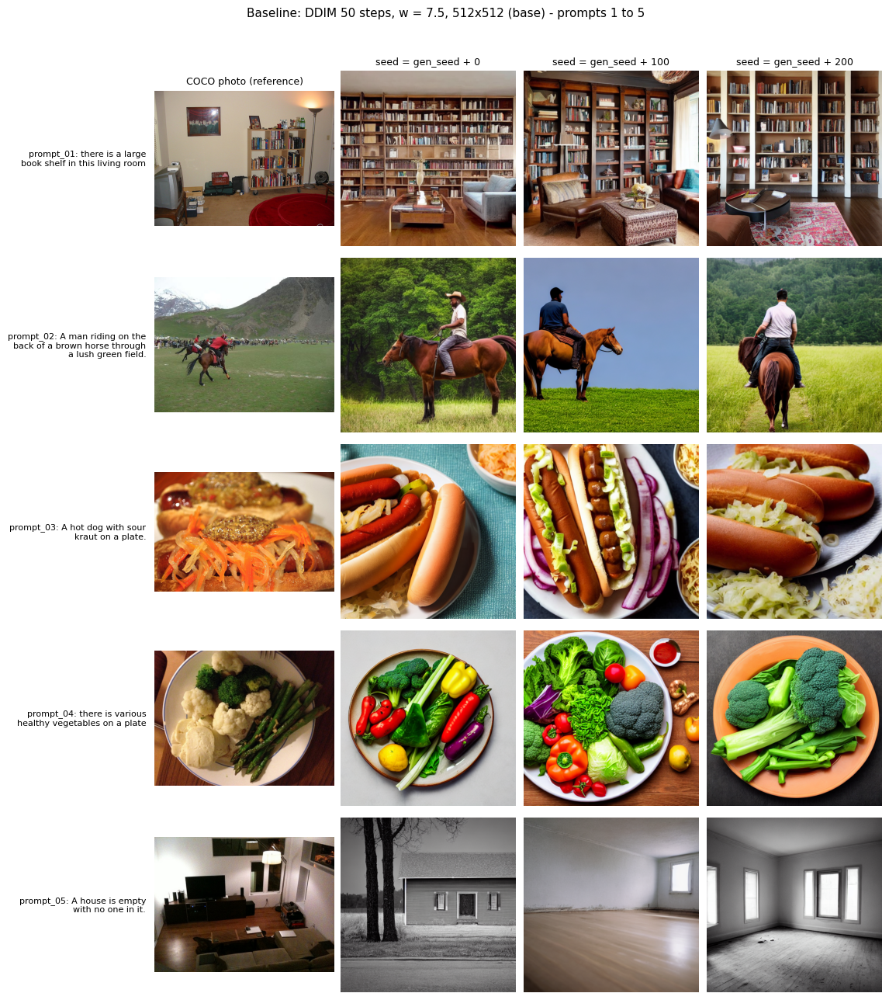

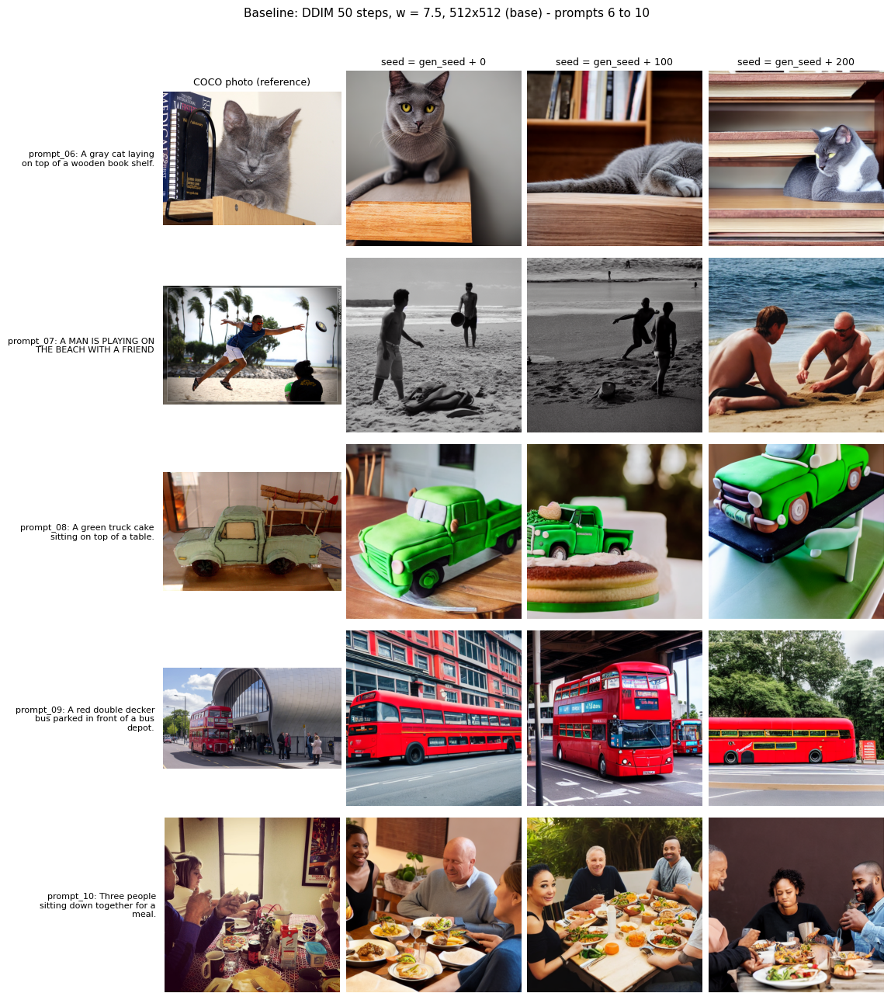

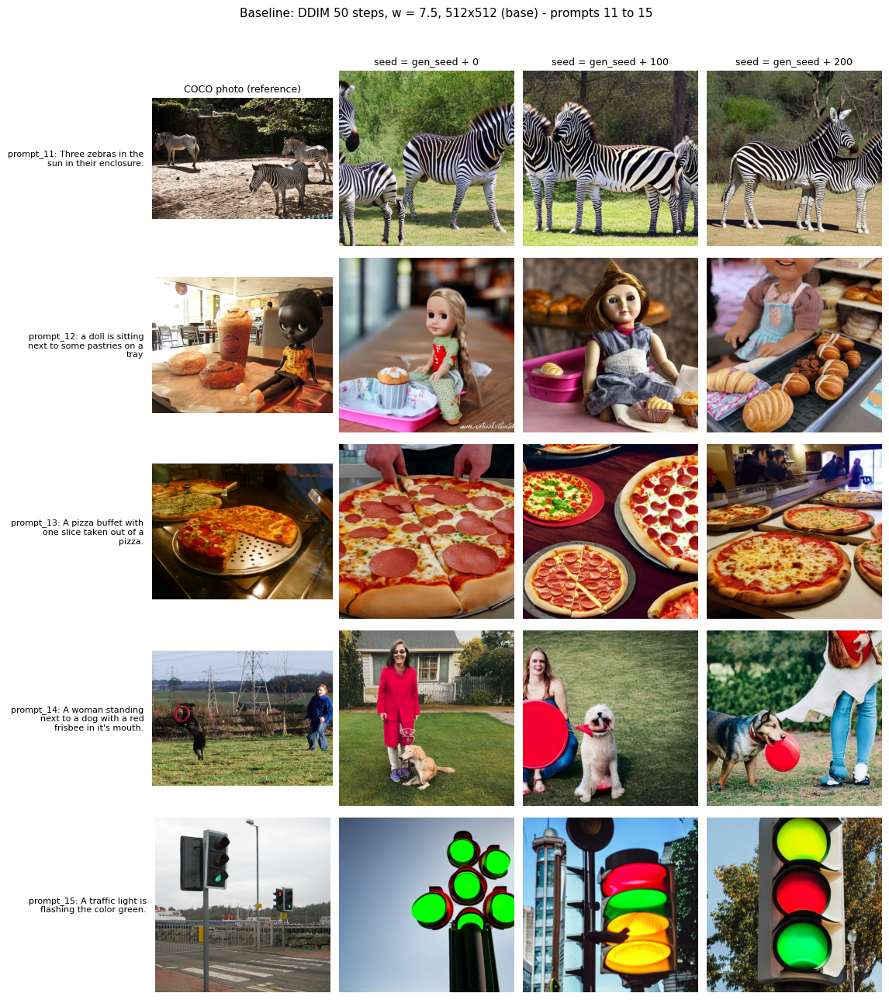

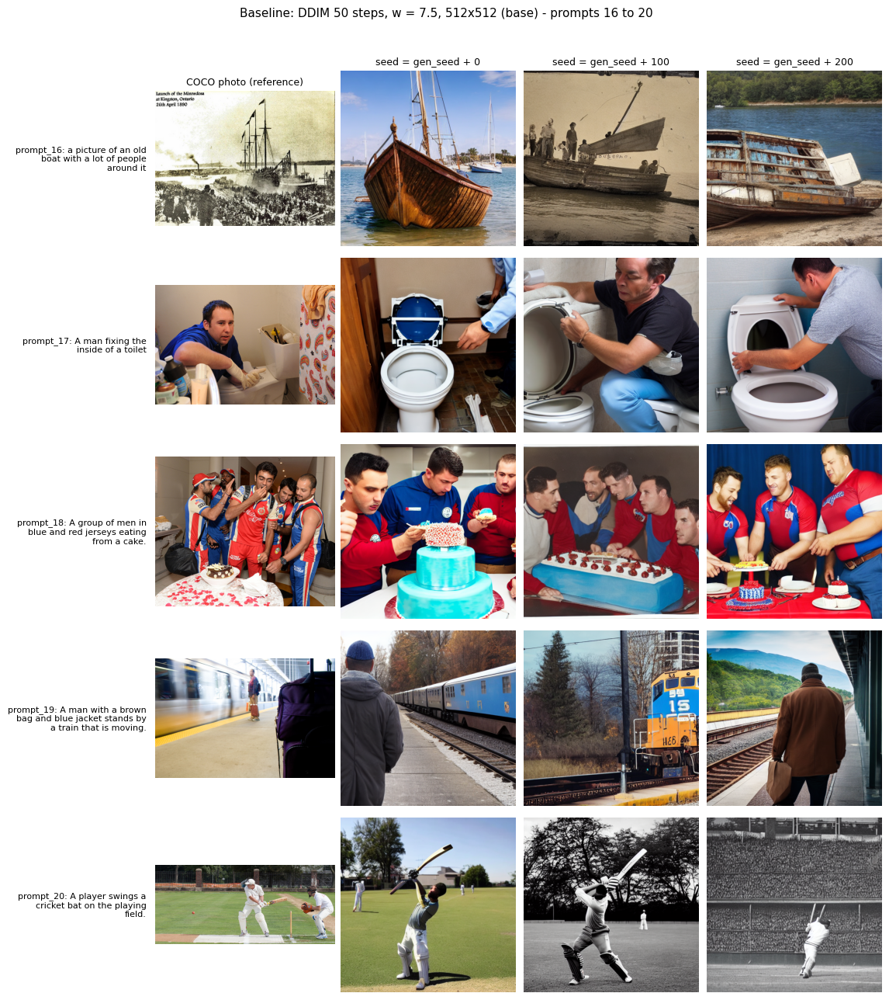

In [7]:
# Baseline gallery: 5 prompts per figure, reference photo + 3 seeds
for page in range(4):
    chunk = baseline[page * 5:(page + 1) * 5]
    grid, labels = [], []
    for b in chunk:
        rs = sorted(per_prompt[b["prompt_id"]], key=lambda r: r["seed"])
        grid.append([Image.open(BASELINE_DIR / b["local_reference_image"]).convert("RGB")] +
                    [t2i.load_image(BASE_DIR, r) for r in rs])
        labels.append(f"{b['prompt_id']}: {b['prompt']}")
    seeds_txt = ["COCO photo (reference)"] + [f"seed = gen_seed + {o}" for o in SEED_OFFSETS]
    fig = t2i.labeled_grid(grid, labels, seeds_txt, cell=2.5, row_label_width=30,
                           title=f"Baseline: DDIM 50 steps, w = 7.5, 512x512 ({TAG}) - prompts {page * 5 + 1} to {page * 5 + 5}")
    fig.savefig(FIG_DIR / f"20_baseline_{TAG}_{page + 1}.png", dpi=110, bbox_inches="tight")
    plt.show()

**Observations (TODO after the run):**

## 3. Guidance-scale sweep

The classifier-free guidance scale w sets how far each step moves from the unconditional prediction toward the text-conditioned one. Every other setting stays at the baseline (DDIM, 50 steps), on 6 varied prompts x 3 seeds x 7 scales:

- **w = 0**: unconditional, the text is ignored. This is the floor for prompt alignment.
- **w = 1**: conditional branch only, no guidance. One UNet pass per step, so about half the cost.
- **w = 3 to 15**: increasing guidance; 7.5 is the baseline.

The prompts cover a scene (01), an animal with attributes (02), food (03), a colored vehicle (09), counting (11) and a multi-object relation (14). The 18 images at w = 7.5 are copied from Section 2 when they were made with the same torch version as this run. Otherwise they are generated again, because a different torch version turns the same seed into different starting noise.

In [8]:
# Sweep settings and helpers shared by Sections 3 to 5
import shutil

SWEEP_PIDS = ["prompt_01", "prompt_02", "prompt_03", "prompt_09", "prompt_11", "prompt_14"]
GUIDANCE_SCALES = [0, 1, 3, 5, 7.5, 10, 15]
CONV_KEYS = ("psnr_vs_ref", "clip_sim_vs_ref")   # convergence metrics, Sections 4 and 5

TORCH_VERSION = t2i.environment_info()["torch"]

def made_here(json_path):
    """True if an image was generated with this run's torch version (the same seed gives
    different starting noise under another version, so those images are not comparable)."""
    return t2i.read_json(json_path)["environment"].get("torch") == TORCH_VERSION

def reuse_baseline(jobs, out_dir):
    """Copy Section 2 images whose settings match a job, so they are not generated twice.
    Copies made under another torch version are removed so they are generated again."""
    out_dir.mkdir(parents=True, exist_ok=True)
    reused = removed = 0
    for j in jobs:
        name = t2i.job_name(j)
        target, source = out_dir / f"{name}.json", BASE_DIR / f"{name}.json"
        if target.exists() and not made_here(target):
            for ext in ("png", "json"):
                (out_dir / f"{name}.{ext}").unlink(missing_ok=True)
            removed += 1
        if not target.exists() and source.exists() and made_here(source):
            for ext in ("png", "json"):
                shutil.copy(BASE_DIR / f"{name}.{ext}", out_dir / f"{name}.{ext}")
            reused += 1
    print(f"Reused {reused} baseline images; removed {removed} made with another torch version")

def summarize(records, fields, extra=()):
    """One row per setting, averaged over prompts and seeds. fields(record) returns the
    setting columns, e.g. {"guidance_scale": 7.5}; extra lists more per-image metrics to average."""
    groups = defaultdict(list)
    for r in records:
        groups[json.dumps(fields(r), sort_keys=True)].append(r)
    rows = []
    for key, rs in groups.items():
        by_prompt = defaultdict(list)
        for r in rs:
            by_prompt[r["prompt_id"]].append(r["_emb"])
        div = [t2i.pairwise_diversity(torch.stack(e)) for e in by_prompt.values() if len(e) > 1]
        clip = [r["clip_score"] for r in rs]
        row = {**json.loads(key), "n_images": len(rs),
               "clip_score": float(np.mean(clip)), "clip_score_std": float(np.std(clip)),
               "top1": float(np.mean([r["top1"] for r in rs])),
               "saturation": float(np.mean([r["saturation"] for r in rs])),
               "seed_diversity": float(np.mean(div)) if div else None,
               "sec_per_image": float(np.mean([r["timings"]["per_image_s"] for r in rs])),
               "gpu_minutes": float(sum(r["timings"]["per_image_s"] for r in rs) / 60),
               "peak_memory_mb": max((r["peak_memory_mb"] or 0) for r in rs)}
        for k in extra:
            vals = [r[k] for r in rs if k in r]
            row[k] = float(np.mean(vals)) if vals else None
        rows.append(row)
    return rows

def show_table(rows, cols):
    print(" | ".join(f"{k:>16}" for k in cols))
    for r in rows:
        print(" | ".join(f"{r[k]:>16.3f}" if isinstance(r[k], float) else f"{str(r[k] if r[k] is not None else '-'):>16}"
                         for k in cols))

In [9]:
# Generate the guidance sweep: 126 images
GUIDE_DIR = GEN_DIR / f"guidance_{TAG}"
guide_jobs = [job(pid, off, guidance_scale=w)
              for w in GUIDANCE_SCALES for pid in SWEEP_PIDS for off in SEED_OFFSETS]
reuse_baseline(guide_jobs, GUIDE_DIR)
t0 = time.perf_counter()
guide_records = t2i.run_jobs(c, guide_jobs, GUIDE_DIR, batch_size=BATCH_SIZE, image_format="png")
print(f"Wall time: {(time.perf_counter() - t0) / 60:.1f} min")

Reused 18 baseline images
  4/108 new | ddim n=50 w=0 | 6.19 s/image
  8/108 new | ddim n=50 w=0 | 6.21 s/image
  12/108 new | ddim n=50 w=0 | 6.35 s/image
  16/108 new | ddim n=50 w=0 | 6.52 s/image
  18/108 new | ddim n=50 w=0 | 6.99 s/image
  22/108 new | ddim n=50 w=1 | 3.64 s/image
  26/108 new | ddim n=50 w=1 | 3.65 s/image
  30/108 new | ddim n=50 w=1 | 3.63 s/image
  34/108 new | ddim n=50 w=1 | 3.60 s/image
  36/108 new | ddim n=50 w=1 | 3.98 s/image
  40/108 new | ddim n=50 w=3 | 6.67 s/image
  44/108 new | ddim n=50 w=3 | 6.70 s/image
  48/108 new | ddim n=50 w=3 | 6.71 s/image
  52/108 new | ddim n=50 w=3 | 6.68 s/image
  54/108 new | ddim n=50 w=3 | 7.00 s/image
  58/108 new | ddim n=50 w=5 | 6.66 s/image
  62/108 new | ddim n=50 w=5 | 6.67 s/image
  66/108 new | ddim n=50 w=5 | 6.69 s/image
  70/108 new | ddim n=50 w=5 | 6.70 s/image
  72/108 new | ddim n=50 w=5 | 7.02 s/image
  76/108 new | ddim n=50 w=10 | 6.70 s/image
  80/108 new | ddim n=50 w=10 | 6.68 s/image
  84/1

In [10]:
# Score each image and summarize per guidance scale
score(guide_records, GUIDE_DIR)
guide_rows = summarize(guide_records, lambda r: {"guidance_scale": r["guidance_scale"]})
sweep_photo_score = float(np.mean([ref_scores[pidx[p]] for p in SWEEP_PIDS]))

t2i.write_json(LOG_DIR / f"guidance_{TAG}_summary.json", {
    "settings": {"sampler": BASE["sampler"], "steps": BASE["steps"], "prompts": SWEEP_PIDS,
                 "seed_offsets": SEED_OFFSETS, "guidance_scales": GUIDANCE_SCALES, "variant": TAG},
    "clip_score_reference_photos": sweep_photo_score,
    "rows": guide_rows})

print(f"Real-photo CLIP score for these 6 prompts: {sweep_photo_score:.1f}\n")
show_table(guide_rows, ["guidance_scale", "clip_score", "top1", "seed_diversity", "saturation",
                        "sec_per_image", "peak_memory_mb"])

Real-photo CLIP score for these 6 prompts: 30.8

  guidance_scale |       clip_score |             top1 |   seed_diversity |       saturation |    sec_per_image |   peak_memory_mb
               0 |           13.743 |            0.000 |            0.404 |            0.238 |            6.393 |         5080.200
               1 |           27.405 |            0.889 |            0.268 |            0.272 |            3.669 |         5078.500
               3 |           31.026 |            1.000 |            0.172 |            0.336 |            6.723 |         5080.200
               5 |           31.366 |            1.000 |            0.138 |            0.379 |            6.718 |         5080.200
           7.500 |           32.288 |            1.000 |            0.128 |            0.442 |            6.503 |         5080.900
              10 |           31.964 |            1.000 |            0.119 |            0.464 |            6.723 |         5080.200
              15 |           32.16

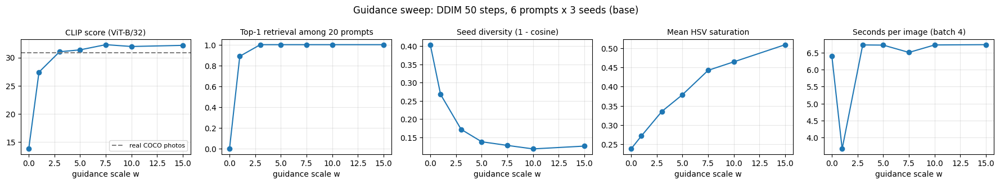

In [11]:
# Alignment, diversity, saturation and cost against guidance scale
ws = [r["guidance_scale"] for r in guide_rows]
panels = [("clip_score", "CLIP score (ViT-B/32)"), ("top1", "Top-1 retrieval among 20 prompts"),
          ("seed_diversity", "Seed diversity (1 - cosine)"), ("saturation", "Mean HSV saturation"),
          ("sec_per_image", "Seconds per image (batch 4)")]
fig, axes = plt.subplots(1, len(panels), figsize=(3.6 * len(panels), 3.3))
for ax, (k, label) in zip(axes, panels):
    ax.plot(ws, [r[k] for r in guide_rows], "o-")
    ax.set_xlabel("guidance scale w")
    ax.set_title(label, fontsize=10)
    ax.grid(alpha=0.3)
axes[0].axhline(sweep_photo_score, ls="--", c="gray", label="real COCO photos")
axes[0].legend(fontsize=8)
fig.suptitle(f"Guidance sweep: DDIM 50 steps, {len(SWEEP_PIDS)} prompts x {len(SEED_OFFSETS)} seeds ({TAG})")
fig.tight_layout()
fig.savefig(FIG_DIR / f"30_guidance_metrics_{TAG}.png", dpi=110, bbox_inches="tight")
plt.show()

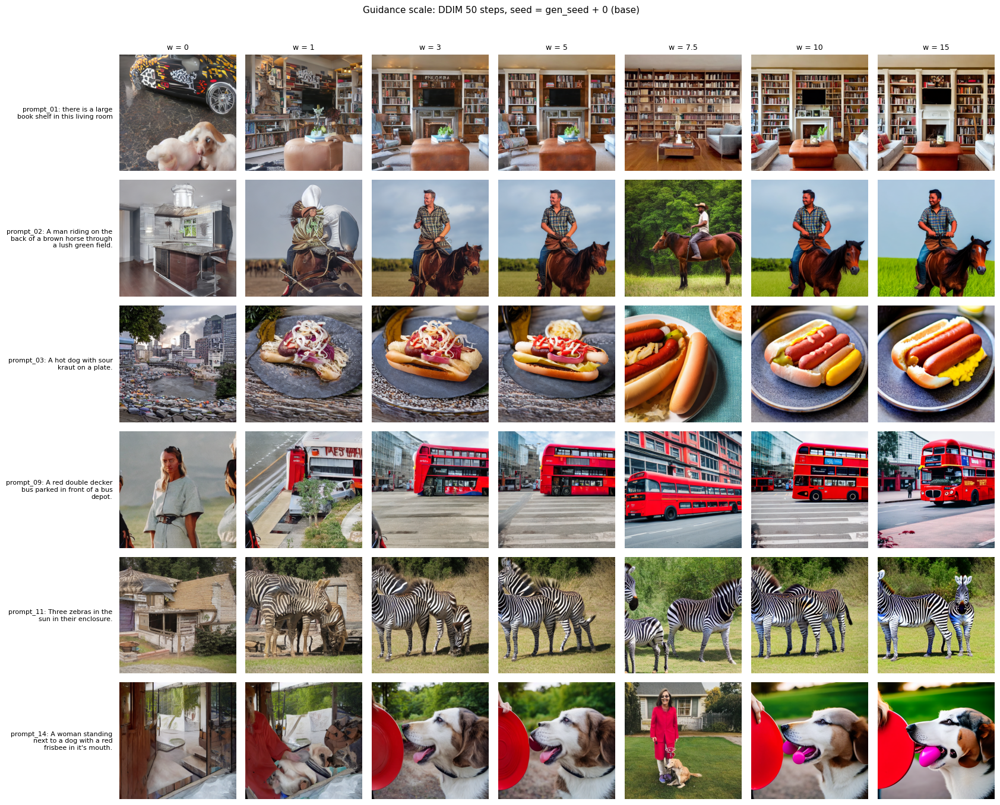

In [12]:
# Prompts x guidance scale, first seed
guide_by = {(r["prompt_id"], r["guidance_scale"], r["seed_offset"]): r for r in guide_records}
grid = [[t2i.load_image(GUIDE_DIR, guide_by[(p, w, SEED_OFFSETS[0])]) for w in GUIDANCE_SCALES]
        for p in SWEEP_PIDS]
fig = t2i.labeled_grid(grid, [f"{p}: {by_id[p]['prompt']}" for p in SWEEP_PIDS],
                       [f"w = {w:g}" for w in GUIDANCE_SCALES], cell=2.2, row_label_width=30,
                       title=f"Guidance scale: DDIM 50 steps, seed = gen_seed + {SEED_OFFSETS[0]} ({TAG})")
fig.savefig(FIG_DIR / f"30_guidance_grid_{TAG}.png", dpi=110, bbox_inches="tight")
plt.show()

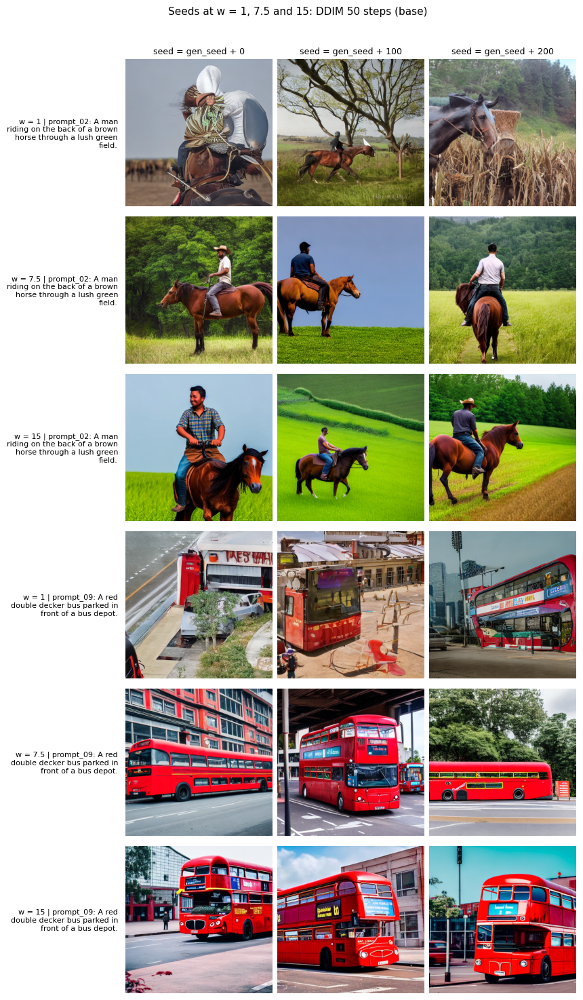

In [13]:
# Seed diversity at no guidance, the baseline and strong guidance
DIVERSITY_PIDS = ["prompt_02", "prompt_09"]
DIVERSITY_WS = [1, 7.5, 15]
grid, labels = [], []
for p in DIVERSITY_PIDS:
    for w in DIVERSITY_WS:
        grid.append([t2i.load_image(GUIDE_DIR, guide_by[(p, w, off)]) for off in SEED_OFFSETS])
        labels.append(f"w = {w:g} | {p}: {by_id[p]['prompt']}")
fig = t2i.labeled_grid(grid, labels, [f"seed = gen_seed + {o}" for o in SEED_OFFSETS], cell=2.4,
                       row_label_width=30, title=f"Seeds at w = 1, 7.5 and 15: DDIM 50 steps ({TAG})")
fig.savefig(FIG_DIR / f"30_guidance_seeds_{TAG}.png", dpi=110, bbox_inches="tight")
plt.show()

**Observations (TODO after the run):**

## 4. Samplers and step counts (Task 4)

Seven samplers x {10, 20, 50} steps on the same 6 prompts with one seed, at w = 7.5. DDIM, PNDM, Euler and DPM++ 2M (with and without Karras) are deterministic solvers of the same probability-flow ODE, so from the same starting noise they converge to the same image as the step count grows. A 100-step DPM++ 2M run is the near-converged reference, and two numbers measure how close each faster setting gets to it:

- **PSNR to the reference** (pixel level, in dB);
- **CLIP image similarity to the reference** (content level).

DDPM and Euler-a add fresh noise at every step and converge to different images, so they are judged by CLIP score against the prompt and by eye. Their lines are dashed in the plots.

In [14]:
# Generate the sampler x steps sweep (126 images) and the 100-step reference (6 images)
SAMPLER_NAMES = list(t2i.SAMPLERS)
STEP_COUNTS = [10, 20, 50]
REF = dict(sampler="dpmpp_2m", steps=100, variant="reference")
SAMPLER_DIR = GEN_DIR / f"samplers_{TAG}"
REF_DIR = GEN_DIR / f"reference_{TAG}"

ref_jobs = [job(pid, **REF) for pid in SWEEP_PIDS]
sampler_jobs = [job(pid, sampler=s, steps=n) for s in SAMPLER_NAMES for n in STEP_COUNTS for pid in SWEEP_PIDS]
reuse_baseline(sampler_jobs, SAMPLER_DIR)   # DDIM 50 is the baseline setting
t0 = time.perf_counter()
ref_records = t2i.run_jobs(c, ref_jobs, REF_DIR, batch_size=BATCH_SIZE, image_format="png")
sampler_records = t2i.run_jobs(c, sampler_jobs, SAMPLER_DIR, batch_size=BATCH_SIZE, image_format="png")
print(f"Wall time: {(time.perf_counter() - t0) / 60:.1f} min")

Reused 6 baseline images
  4/6 new | dpmpp_2m n=100 w=7.5 | 13.36 s/image
  6/6 new | dpmpp_2m n=100 w=7.5 | 13.58 s/image
6 images in outputs/generated/reference_base (0 reused)
  4/120 new | ddpm n=10 w=7.5 | 1.51 s/image
  6/120 new | ddpm n=10 w=7.5 | 1.58 s/image
  10/120 new | ddpm n=20 w=7.5 | 2.81 s/image
  12/120 new | ddpm n=20 w=7.5 | 2.96 s/image
  16/120 new | ddpm n=50 w=7.5 | 6.79 s/image
  18/120 new | ddpm n=50 w=7.5 | 7.04 s/image
  22/120 new | ddim n=10 w=7.5 | 1.53 s/image
  24/120 new | ddim n=10 w=7.5 | 1.58 s/image
  28/120 new | ddim n=20 w=7.5 | 2.80 s/image
  30/120 new | ddim n=20 w=7.5 | 2.94 s/image
  34/120 new | pndm n=10 w=7.5 | 1.65 s/image
  36/120 new | pndm n=10 w=7.5 | 1.72 s/image
  40/120 new | pndm n=20 w=7.5 | 2.94 s/image
  42/120 new | pndm n=20 w=7.5 | 3.08 s/image
  46/120 new | pndm n=50 w=7.5 | 6.84 s/image
  48/120 new | pndm n=50 w=7.5 | 7.15 s/image
  52/120 new | euler n=10 w=7.5 | 1.52 s/image
  54/120 new | euler n=10 w=7.5 | 1.59 s

In [15]:
# Score, then measure each image's distance to the 100-step reference
score(ref_records, REF_DIR)
score(sampler_records, SAMPLER_DIR)
ref_by_pid = {r["prompt_id"]: r for r in ref_records}
ref_img = {p: t2i.load_image(REF_DIR, r) for p, r in ref_by_pid.items()}

def add_convergence(records, out_dir):
    for r in records:
        ref = ref_by_pid[r["prompt_id"]]
        r["psnr_vs_ref"] = t2i.psnr(t2i.load_image(out_dir, r), ref_img[r["prompt_id"]])
        r["clip_sim_vs_ref"] = float(r["_emb"] @ ref["_emb"])
    return records

add_convergence(sampler_records, SAMPLER_DIR)
sampler_rows = summarize(sampler_records, lambda r: {"sampler": r["sampler"], "steps": r["steps"]}, CONV_KEYS)
for r in sampler_rows:
    r["stochastic"] = r["sampler"] in t2i.STOCHASTIC_SAMPLERS
ref_clip = float(np.mean([r["clip_score"] for r in ref_records]))

t2i.write_json(LOG_DIR / f"samplers_{TAG}_summary.json", {
    "settings": {"guidance_scale": BASE["guidance_scale"], "prompts": SWEEP_PIDS, "seed_offset": 0,
                 "samplers": SAMPLER_NAMES, "steps": STEP_COUNTS, "reference": REF, "variant": TAG},
    "reference_clip_score": ref_clip,
    "reference_sec_per_image": float(np.mean([r["timings"]["per_image_s"] for r in ref_records])),
    "rows": sampler_rows})

print(f"Reference (DPM++ 2M, 100 steps) CLIP score: {ref_clip:.1f}\n")
show_table(sampler_rows, ["sampler", "steps", "psnr_vs_ref", "clip_sim_vs_ref", "clip_score", "sec_per_image"])

Reference (DPM++ 2M, 100 steps) CLIP score: 32.2

         sampler |            steps |      psnr_vs_ref |  clip_sim_vs_ref |       clip_score |    sec_per_image
            ddpm |               10 |           10.668 |            0.833 |           31.818 |            1.533
            ddpm |               20 |           10.393 |            0.890 |           32.659 |            2.864
            ddpm |               50 |            9.918 |            0.893 |           31.812 |            6.873
            ddim |               10 |           12.790 |            0.875 |           32.846 |            1.545
            ddim |               20 |           16.060 |            0.922 |           31.982 |            2.845
            ddim |               50 |            8.398 |            0.850 |           31.327 |            6.510
            pndm |               10 |           12.105 |            0.845 |           31.203 |            1.675
            pndm |               20 |           15.853

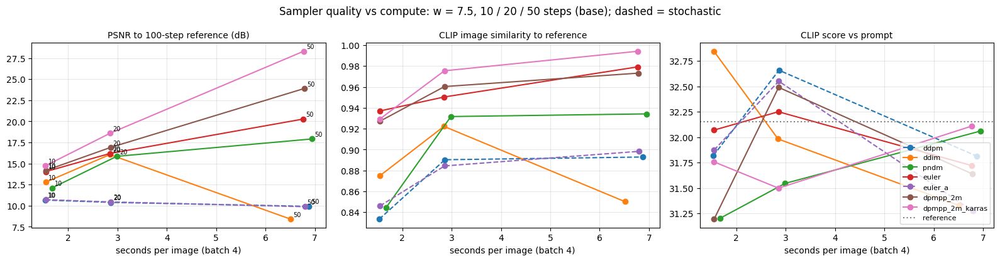

In [16]:
# Quality against compute: one line per sampler, points labeled by step count
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
titles = {"psnr_vs_ref": "PSNR to 100-step reference (dB)",
          "clip_sim_vs_ref": "CLIP image similarity to reference",
          "clip_score": "CLIP score vs prompt"}
for s in SAMPLER_NAMES:
    rs = sorted([r for r in sampler_rows if r["sampler"] == s], key=lambda r: r["steps"])
    x = [r["sec_per_image"] for r in rs]
    style = "o--" if s in t2i.STOCHASTIC_SAMPLERS else "o-"
    for ax, k in zip(axes, titles):
        ax.plot(x, [r[k] for r in rs], style, label=s)
    for r in rs:
        axes[0].annotate(str(r["steps"]), (r["sec_per_image"], r["psnr_vs_ref"]), fontsize=7,
                         xytext=(3, 3), textcoords="offset points")
for ax, t in zip(axes, titles.values()):
    ax.set_title(t, fontsize=10)
    ax.set_xlabel("seconds per image (batch 4)")
    ax.grid(alpha=0.3)
axes[2].axhline(ref_clip, ls=":", c="gray", label="reference")
axes[2].legend(fontsize=8, loc="lower right")
fig.suptitle(f"Sampler quality vs compute: w = {BASE['guidance_scale']}, 10 / 20 / 50 steps ({TAG}); dashed = stochastic")
fig.tight_layout()
fig.savefig(FIG_DIR / f"40_samplers_quality_vs_compute_{TAG}.png", dpi=110, bbox_inches="tight")
plt.show()

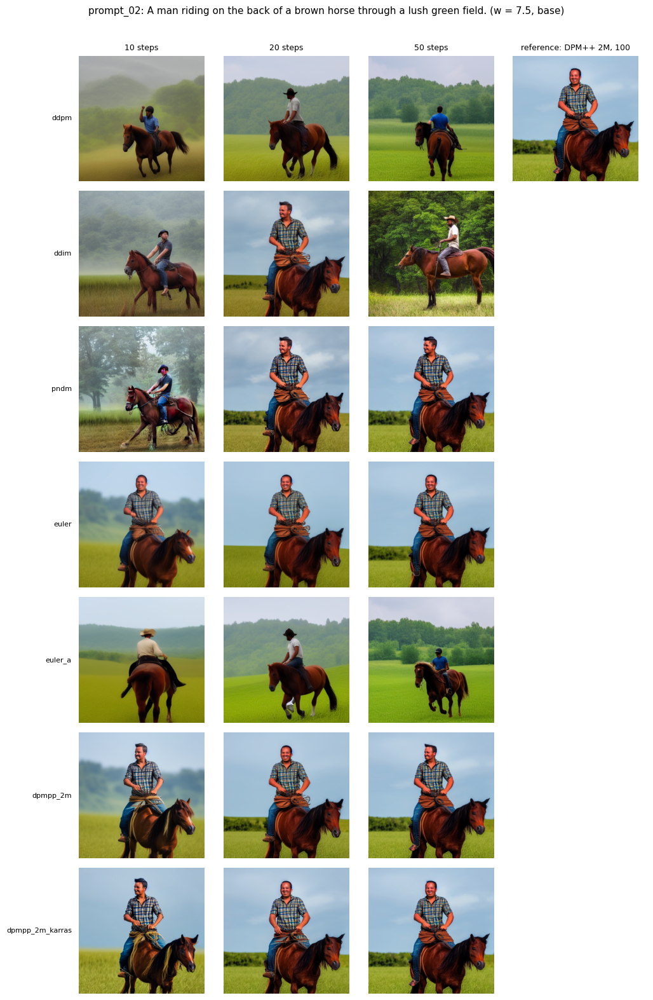

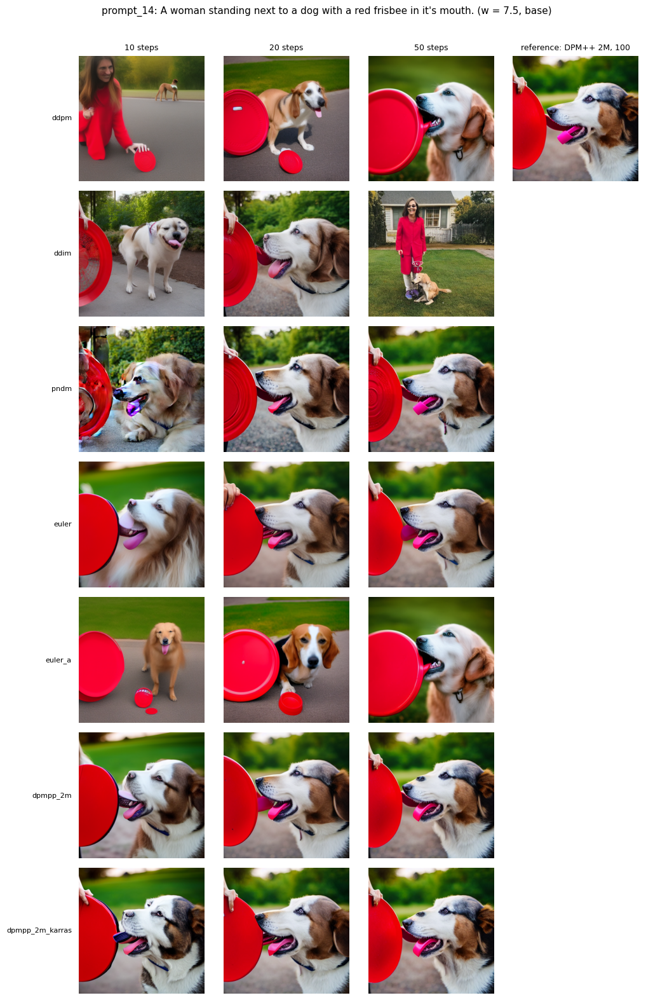

In [17]:
# Samplers x step count for two prompts, with the reference in the last column
SAMPLER_GRID_PIDS = ["prompt_02", "prompt_14"]
sampler_by = {(r["sampler"], r["steps"], r["prompt_id"]): r for r in sampler_records}
for p in SAMPLER_GRID_PIDS:
    grid = [[t2i.load_image(SAMPLER_DIR, sampler_by[(s, n, p)]) for n in STEP_COUNTS] +
            [ref_img[p] if i == 0 else None] for i, s in enumerate(SAMPLER_NAMES)]
    fig = t2i.labeled_grid(grid, SAMPLER_NAMES, [f"{n} steps" for n in STEP_COUNTS] + ["reference: DPM++ 2M, 100"],
                           cell=2.2, row_label_width=16, title=f"{p}: {by_id[p]['prompt']} (w = 7.5, {TAG})")
    fig.savefig(FIG_DIR / f"40_samplers_grid_{p}_{TAG}.png", dpi=110, bbox_inches="tight")
    plt.show()

**Observations (TODO after the run)::**

## 5. Noise schedule (Task 4)

SD 1.5 learned its noise prediction under one training schedule (`scaled_linear` from 0.00085 to 0.012 over 1,000 steps), so the schedule cannot be swapped without re-training. This section varies how the sampler moves through that schedule, and runs one deliberate train/inference mismatch:

1. **Training schedules compared** (no generation): how much signal remains at each step, and the log signal-to-noise ratio, for the scaled-linear, linear and cosine beta schedules.
2. **Timestep spacing**: DDIM at 10 and 20 steps with `leading` (the SD 1.5 default), `trailing` and `linspace` spacing.
3. **Karras sigma spacing**: DPM++ 2M with and without Karras, from the Section 4 images.
4. **Mismatched beta schedule**: DDIM at 50 steps sampling with linear and cosine beta schedules instead of the trained schedule.

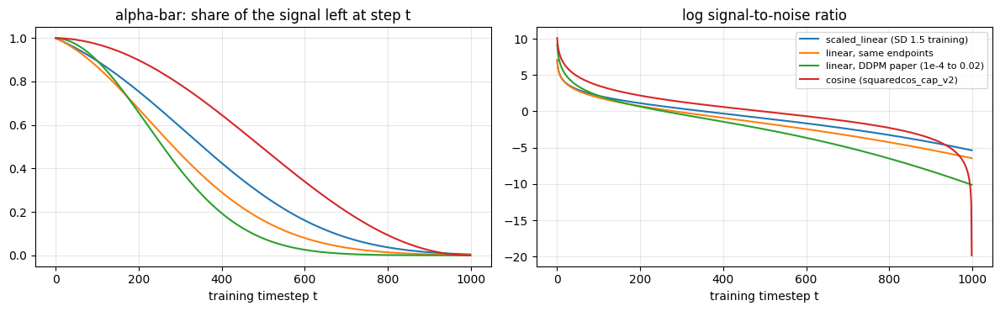

In [18]:
# Training noise schedules: alpha_bar_t and log-SNR (no GPU needed)
curves = t2i.schedule_curves(c.scheduler_config)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for label, cv in curves.items():
    axes[0].plot(cv["alpha_bar"], label=label)
    axes[1].plot(cv["log_snr"], label=label)
axes[0].set(title="alpha-bar: share of the signal left at step t", xlabel="training timestep t")
axes[1].set(title="log signal-to-noise ratio", xlabel="training timestep t")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / f"51_schedule_curves_{TAG}.png", dpi=110, bbox_inches="tight")
plt.show()

In [19]:
# Timestep spacing: which training timesteps DDIM visits
SPACINGS = ["leading", "trailing", "linspace"]
SPACING_STEPS = [10, 20]
spacing_timesteps = {}
for sp in SPACINGS:
    s = t2i.make_scheduler("ddim", c.scheduler_config, timestep_spacing=sp)
    s.set_timesteps(10)
    spacing_timesteps[sp] = s.timesteps.tolist()
    print(f"{sp:>9}, 10 steps: {spacing_timesteps[sp]}")

  leading, 10 steps: [901, 801, 701, 601, 501, 401, 301, 201, 101, 1]
 trailing, 10 steps: [999, 899, 799, 699, 599, 499, 399, 299, 199, 99]
 linspace, 10 steps: [999, 888, 777, 666, 555, 444, 333, 222, 111, 0]


In [20]:
# Generate the spacing runs: 3 spacings x 2 step counts x 6 prompts = 36 images
SPACING_DIR = GEN_DIR / f"spacing_{TAG}"
spacing_jobs = [job(pid, steps=n, scheduler_overrides={"timestep_spacing": sp}, variant=sp)
                for sp in SPACINGS for n in SPACING_STEPS for pid in SWEEP_PIDS]
spacing_records = t2i.run_jobs(c, spacing_jobs, SPACING_DIR, batch_size=BATCH_SIZE, image_format="png")
score(spacing_records, SPACING_DIR)
add_convergence(spacing_records, SPACING_DIR)
spacing_rows = summarize(spacing_records, lambda r: {"timestep_spacing": r["variant"], "steps": r["steps"]},
                         CONV_KEYS)
show_table(spacing_rows, ["timestep_spacing", "steps", "psnr_vs_ref", "clip_sim_vs_ref", "clip_score",
                          "saturation"])

  4/36 new | ddim n=10 w=7.5 | 1.51 s/image
  6/36 new | ddim n=10 w=7.5 | 1.58 s/image
  10/36 new | ddim n=20 w=7.5 | 2.86 s/image
  12/36 new | ddim n=20 w=7.5 | 3.07 s/image
  16/36 new | ddim n=10 w=7.5 | 1.59 s/image
  18/36 new | ddim n=10 w=7.5 | 1.64 s/image
  22/36 new | ddim n=20 w=7.5 | 2.85 s/image
  24/36 new | ddim n=20 w=7.5 | 2.93 s/image
  28/36 new | ddim n=10 w=7.5 | 1.51 s/image
  30/36 new | ddim n=10 w=7.5 | 1.58 s/image
  34/36 new | ddim n=20 w=7.5 | 2.77 s/image
  36/36 new | ddim n=20 w=7.5 | 2.92 s/image
36 images in outputs/generated/spacing_base (0 reused)
timestep_spacing |            steps |      psnr_vs_ref |  clip_sim_vs_ref |       clip_score |       saturation
         leading |               10 |           12.790 |            0.875 |           32.846 |            0.342
         leading |               20 |           16.060 |            0.922 |           31.982 |            0.380
        trailing |               10 |           14.368 |            0.9

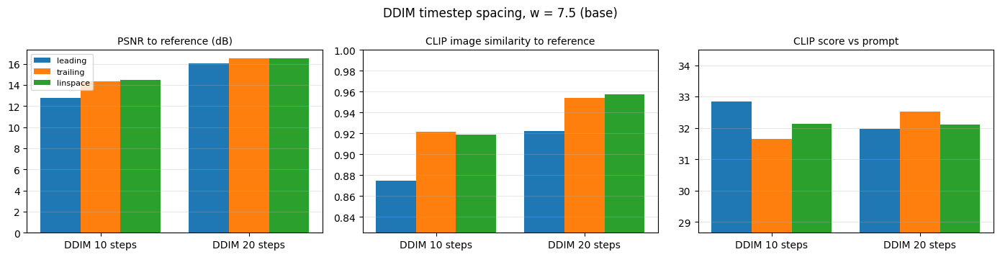

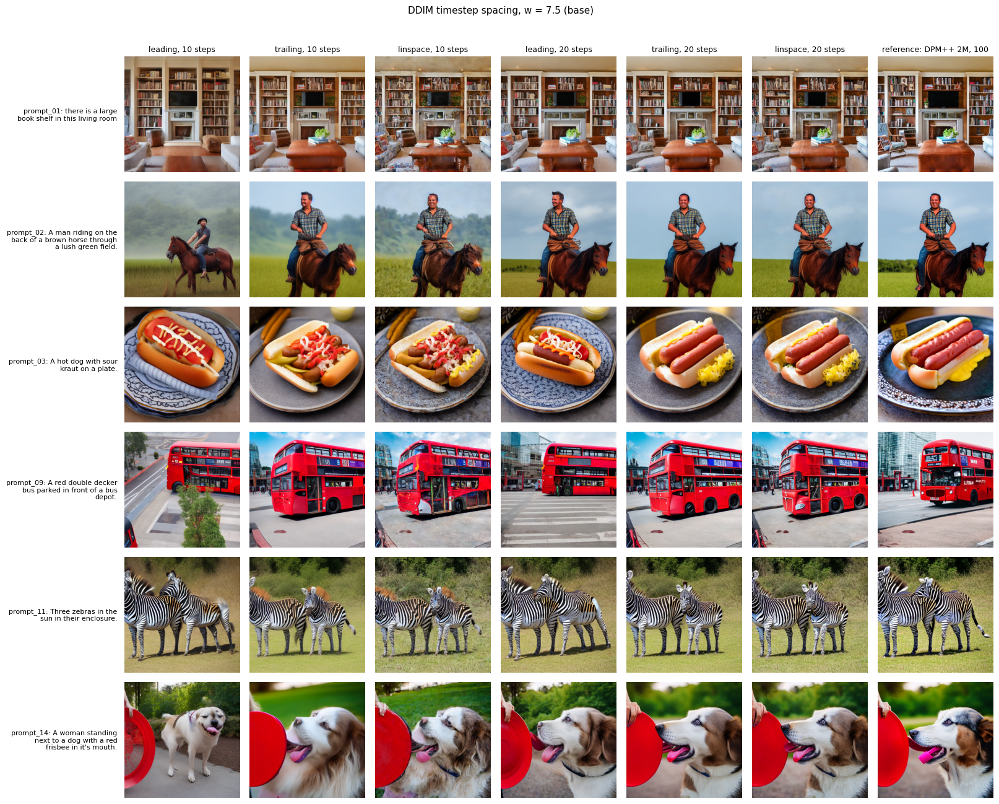

In [21]:
# Spacing metrics and image grid
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
xpos = np.arange(len(SPACING_STEPS))
for i, sp in enumerate(SPACINGS):
    rs = sorted([r for r in spacing_rows if r["timestep_spacing"] == sp], key=lambda r: r["steps"])
    for ax, k in zip(axes, ["psnr_vs_ref", "clip_sim_vs_ref", "clip_score"]):
        ax.bar(xpos + (i - 1) * 0.27, [r[k] for r in rs], width=0.27, label=sp)
for ax, t in zip(axes, ["PSNR to reference (dB)", "CLIP image similarity to reference", "CLIP score vs prompt"]):
    ax.set_xticks(xpos, [f"DDIM {n} steps" for n in SPACING_STEPS])
    ax.set_title(t, fontsize=10)
    ax.grid(alpha=0.3, axis="y")
axes[1].set_ylim(min(r["clip_sim_vs_ref"] for r in spacing_rows) - 0.05, 1)
axes[2].set_ylim(min(r["clip_score"] for r in spacing_rows) - 3, None)
axes[0].legend(fontsize=8)
fig.suptitle(f"DDIM timestep spacing, w = 7.5 ({TAG})")
fig.tight_layout()
fig.savefig(FIG_DIR / f"50_spacing_metrics_{TAG}.png", dpi=110, bbox_inches="tight")
plt.show()

spacing_by = {(r["variant"], r["steps"], r["prompt_id"]): r for r in spacing_records}
cols = [(sp, n) for n in SPACING_STEPS for sp in SPACINGS]
grid = [[t2i.load_image(SPACING_DIR, spacing_by[(sp, n, p)]) for sp, n in cols] + [ref_img[p]] for p in SWEEP_PIDS]
fig = t2i.labeled_grid(grid, [f"{p}: {by_id[p]['prompt']}" for p in SWEEP_PIDS],
                       [f"{sp}, {n} steps" for sp, n in cols] + ["reference: DPM++ 2M, 100"],
                       cell=2.1, row_label_width=30, title=f"DDIM timestep spacing, w = 7.5 ({TAG})")
fig.savefig(FIG_DIR / f"50_spacing_grid_{TAG}.png", dpi=110, bbox_inches="tight")
plt.show()

In [22]:
# Karras sigma spacing: DPM++ 2M with and without Karras sigmas (images from Section 4)
# The reference is plain DPM++ 2M, so PSNR slightly favors the non-Karras sampler; compare CLIP score too.
karras_rows = [r for r in sampler_rows if r["sampler"] in ("dpmpp_2m", "dpmpp_2m_karras")]
show_table(karras_rows, ["sampler", "steps", "psnr_vs_ref", "clip_sim_vs_ref", "clip_score", "saturation"])

         sampler |            steps |      psnr_vs_ref |  clip_sim_vs_ref |       clip_score |       saturation
        dpmpp_2m |               10 |           14.179 |            0.927 |           31.192 |            0.413
        dpmpp_2m |               20 |           16.903 |            0.960 |           32.490 |            0.431
        dpmpp_2m |               50 |           23.900 |            0.973 |           31.638 |            0.431
 dpmpp_2m_karras |               10 |           14.735 |            0.929 |           31.757 |            0.443
 dpmpp_2m_karras |               20 |           18.602 |            0.975 |           31.498 |            0.426
 dpmpp_2m_karras |               50 |           28.319 |            0.994 |           32.109 |            0.438


In [23]:
# Mismatched beta schedule at sampling time: DDIM 50 steps, 3 schedules x 6 prompts = 18 images
MISMATCH = {
    "beta-linear": {"beta_schedule": "linear"},                                             # same endpoints
    "beta-linear-ddpm": {"beta_schedule": "linear", "beta_start": 1e-4, "beta_end": 0.02},  # DDPM paper
    "beta-cosine": {"beta_schedule": "squaredcos_cap_v2"},
}
TRAINED_LABEL = "scaled_linear (trained)"
MISMATCH_DIR = GEN_DIR / f"schedule_mismatch_{TAG}"
mismatch_jobs = [job(pid, scheduler_overrides=ov, variant=v) for v, ov in MISMATCH.items() for pid in SWEEP_PIDS]
mismatch_records = t2i.run_jobs(c, mismatch_jobs, MISMATCH_DIR, batch_size=BATCH_SIZE, image_format="png")
score(mismatch_records, MISMATCH_DIR)

# Compare with the DDIM 50 image from the trained schedule (Section 4, same prompt and seed)
trained = {p: sampler_by[("ddim", 50, p)] for p in SWEEP_PIDS}
for r in mismatch_records:
    r["psnr_vs_trained"] = t2i.psnr(t2i.load_image(MISMATCH_DIR, r), t2i.load_image(SAMPLER_DIR, trained[r["prompt_id"]]))
mismatch_rows = summarize(list(trained.values()) + mismatch_records,
                          lambda r: {"schedule": r.get("variant") or TRAINED_LABEL}, ["psnr_vs_trained"])
show_table(mismatch_rows, ["schedule", "clip_score", "top1", "saturation", "psnr_vs_trained"])

  4/18 new | ddim n=50 w=7.5 | 6.75 s/image
  6/18 new | ddim n=50 w=7.5 | 7.15 s/image
  10/18 new | ddim n=50 w=7.5 | 6.65 s/image
  12/18 new | ddim n=50 w=7.5 | 6.94 s/image
  16/18 new | ddim n=50 w=7.5 | 6.66 s/image
  18/18 new | ddim n=50 w=7.5 | 7.01 s/image
18 images in outputs/generated/schedule_mismatch_base (0 reused)
        schedule |       clip_score |             top1 |       saturation |  psnr_vs_trained
scaled_linear (trained) |           31.327 |            1.000 |            0.465 |                -
     beta-linear |           31.865 |            1.000 |            0.497 |            7.524
beta-linear-ddpm |           30.861 |            1.000 |            0.596 |            6.270
     beta-cosine |           32.075 |            1.000 |            0.457 |            8.760


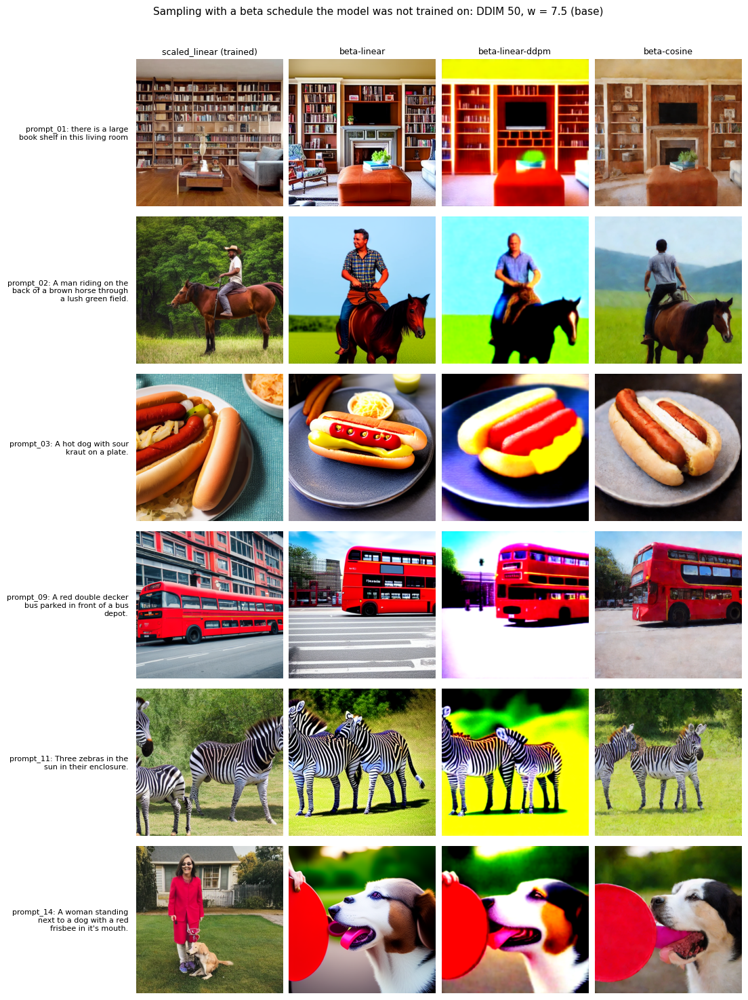

In [24]:
# Mismatch grid: trained schedule vs the three mismatched ones
schedules = [TRAINED_LABEL] + list(MISMATCH)
mismatch_by = {(r["variant"], r["prompt_id"]): r for r in mismatch_records}
grid = [[t2i.load_image(SAMPLER_DIR, trained[p])] + [t2i.load_image(MISMATCH_DIR, mismatch_by[(v, p)]) for v in MISMATCH]
        for p in SWEEP_PIDS]
fig = t2i.labeled_grid(grid, [f"{p}: {by_id[p]['prompt']}" for p in SWEEP_PIDS], schedules, cell=2.4,
                       row_label_width=30, title=f"Sampling with a beta schedule the model was not trained on: DDIM 50, w = 7.5 ({TAG})")
fig.savefig(FIG_DIR / f"51_schedule_mismatch_grid_{TAG}.png", dpi=110, bbox_inches="tight")
plt.show()

t2i.write_json(LOG_DIR / f"noise_schedule_{TAG}_summary.json", {
    "train_schedule": {k: c.scheduler_config.get(k) for k in ["beta_schedule", "beta_start", "beta_end",
                                                              "num_train_timesteps", "timestep_spacing", "steps_offset"]},
    "ddim_timesteps_10_steps": spacing_timesteps,
    "spacing_rows": spacing_rows,
    "karras_rows": karras_rows,
    "mismatch_overrides": MISMATCH,
    "mismatch_rows": mismatch_rows})

**Observations (TODO after the run)::**


## 6. Samples gallery

Joins this notebook's figures (baseline, guidance, samplers, noise schedule) into one PDF for the Canvas "generated samples gallery" deliverable. Every figure carries its prompts and settings in its labels.

In [25]:
# Join the figures into outputs/gallery_<TAG>.pdf
figs = sorted(f for f in FIG_DIR.glob(f"*_{TAG}*.png") if f.name[:2] >= "20")
pages = [Image.open(f).convert("RGB") for f in figs]
gallery_path = OUT_DIR / f"gallery_{TAG}.pdf"
pages[0].save(gallery_path, save_all=True, append_images=pages[1:], resolution=110)
print(f"{len(pages)} figures -> {gallery_path}")
for f in figs:
    print("  ", f.name)

14 figures -> outputs/gallery_base.pdf
   20_baseline_base_1.png
   20_baseline_base_2.png
   20_baseline_base_3.png
   20_baseline_base_4.png
   30_guidance_grid_base.png
   30_guidance_metrics_base.png
   30_guidance_seeds_base.png
   40_samplers_grid_prompt_02_base.png
   40_samplers_grid_prompt_14_base.png
   40_samplers_quality_vs_compute_base.png
   50_spacing_grid_base.png
   50_spacing_metrics_base.png
   51_schedule_curves_base.png
   51_schedule_mismatch_grid_base.png


## 7. Next steps

### 7.1 Fine-tuned variant
After the Part 1 cross-attention fine-tune, call `lora.load_lora(c.unet, OUT_DIR / "lora_run" / "lora", dtype=c.dtype)`, set `TAG = "lora"` and re-run Sections 2 to 6. Outputs land in separate folders, so base and fine-tuned results can be compared prompt by prompt.

### 7.2 Training logs and summary (Task 5)
Copy the numbers from `outputs/logs/guidance_*`, `samplers_*` and `noise_schedule_*_summary.json` into `docs/training_logs_summary.md` (Sections 1 and 4).